In [ ]:
import torch as T
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch import nn
import torch.optim as optim
import torch.nn.functional as F
import os
from torch.utils.data import Dataset
import ast
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from datetime import datetime
import json
import shutil

In [29]:
RELATOR_PADDING = 100

config = {
    'relator_padding' : RELATOR_PADDING,
    'dims' : [RELATOR_PADDING*2*5, 256, 128, 1],
    'activation' : 'tanh',
    'training_data' : 'greedy_search_state_depths.csv',
    'lr' : 1e-3,
    'batch_size' : 2**12,
    'iterations' : 10000,
    'init_from' : None,
    'split_seed' : 1,
    'data_cutoff' : 3,
    
}

device = T.device("cuda" if T.cuda.is_available() else "cpu")
print(device)
print(config['batch_size'])

cuda
4096


# Load Data

In [2]:
df = pd.read_csv('greedy_search_state_depths.csv')
df['state'] = df['state'].apply(ast.literal_eval)
df.head()

,state,depth
0,"((1, 2), (2,))",1
1,"((1, 2, 2), (2,))",2
2,"((1, 2, 2), (-2, -1))",3
3,"((1, 2, 2, 1, 2), (-2, -1))",4
4,"((1, 2, 2, 1, 2), (-2, -1, -2, -1, -2, -2, -1))",5


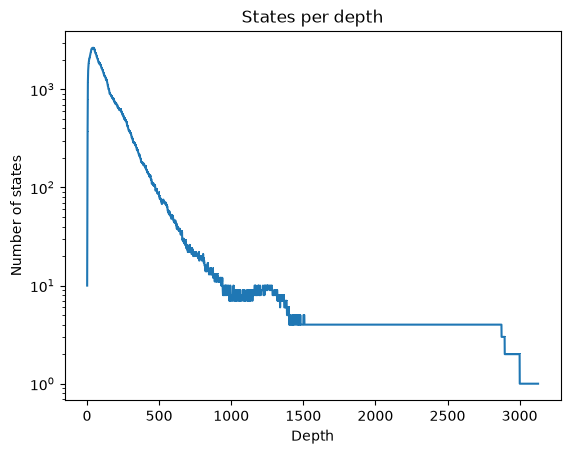

In [3]:
counts = df['depth'].value_counts().sort_index()

counts.plot(marker=',')
plt.xlabel('Depth')
plt.ylabel('Number of states')
plt.yscale('log')
plt.title('States per depth')
plt.show()

In [ ]:
# drop rare and misleading cases

counts = df['depth'].map(df['depth'].value_counts())
df = df[counts >= config['data_cutoff']].reset_index(drop=True)
len(df)

429009

# Make model architecture

In [5]:
# helper functions

activations = {
    'tanh': nn.Tanh,
    'relu': nn.ReLU,}

def mlp(sizes, activation = 'tanh', output_activation=nn.Identity):
    # build a feed forward neural network
    layers = []
    activation = activations.get(activation)

    for j in range(len(sizes)-1):
        act = activation if j < len(sizes) - 2 else output_activation
        layers += [nn.Linear(sizes[j], sizes[j+1]), act()]
    return nn.Sequential(*layers)

def get_training_batch(X, y, batch_size, device):
    idx = T.randint(0, len(X), (batch_size,), device=device)
    xb = F.one_hot(X[idx] + 2, 5).float()
    xb = xb.flatten(1)
    yb = y[idx]
    return xb, yb

In [18]:
# load the network

network = mlp(config['dims'], activation=config['activation']).to(device)

if config['init_from'] is not None:
    if os.path.exists(config['init_from']):
        network.load_state_dict(T.load(config['init_from'], map_location=device))
        print(f'loaded weights from {config["init_from"]}')
    else:
        print("no chekcpoint found, starting from random init")
else:
    print("No init path supplied, starting from random init")

No init path supplied, starting from random init


In [19]:
padded = np.zeros((len(df), 2, RELATOR_PADDING), dtype=np.int8)
for i, s in enumerate(df['state']):
    for j, r in enumerate(s):
        padded[i, j, :len(r)] = r

In [20]:
SPLIT_SEED = 0
idx = np.arange(len(df))

trainval_idx, test_idx = train_test_split(
    idx, test_size=0.15, stratify=df['depth'], random_state=config['split_seed']
)

train_idx, val_idx = train_test_split(
    trainval_idx, test_size=0.25/0.85,
    stratify=df['depth'].iloc[trainval_idx], random_state=config['split_seed'])

In [57]:
X_train = T.tensor(padded[train_idx], dtype=T.long, device=device)
y_train = T.tensor(df['depth'].values[train_idx], dtype=T.float32, device=device)

y_train_mean = T.mean(y_train)
y_train_std = T.std(y_train)
y_train = (y_train - y_train_mean)/y_train_std

X_val = T.tensor(padded[val_idx], dtype=T.long, device=device)
y_val = T.tensor(df['depth'].values[val_idx], dtype=T.float32, device=device)
y_val = (y_val - y_train_mean)/y_train_std

X_test = T.tensor(padded[test_idx], dtype=T.long, device=device)
y_test = T.tensor(df['depth'].values[test_idx], dtype=T.float32, device=device)
y_test = (y_test - y_train_mean)/y_train_std

config["mean"] = y_train_mean.item()
config['std'] = y_train_std.item()

In [58]:
optimizer = optim.Adam(
    network.parameters(),
    lr = config['lr']
)

def train_step(X, y):
    predictions = network(X).squeeze(-1)
    loss = F.mse_loss(predictions, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return loss.item()

In [49]:
losses = []
val_losses = []
X_val_onehot = F.one_hot(X_val + 2, 5).float()
X_val_onehot = X_val_onehot.flatten(1)

for step in range(config['iterations']):
    xb, yb = get_training_batch(X_train, y_train, config['batch_size'], device)
    loss = train_step(xb, yb)
    losses.append((step, loss))

    if step % 500 == 0:
        with T.no_grad():
            y_val_preds = network(X_val_onehot).squeeze(-1)
            val_loss = F.mse_loss(y_val_preds, y_val).item()
            val_losses.append((step, val_loss))
            print(f'train loss on batch at step = {step} is {loss}')
            print(f'val loss on batch at step = {step} is {val_loss}')

train loss on batch at step = 0 is 0.07455277442932129
val loss on batch at step = 0 is 0.11405068635940552
train loss on batch at step = 500 is 0.07624305784702301
val loss on batch at step = 500 is 0.11267910152673721
train loss on batch at step = 1000 is 0.07074649631977081
val loss on batch at step = 1000 is 0.11194276809692383
train loss on batch at step = 1500 is 0.0706404447555542
val loss on batch at step = 1500 is 0.11203789710998535
train loss on batch at step = 2000 is 0.06779375672340393
val loss on batch at step = 2000 is 0.11191215366125107
train loss on batch at step = 2500 is 0.06428871303796768
val loss on batch at step = 2500 is 0.11842555552721024
train loss on batch at step = 3000 is 0.06093115359544754
val loss on batch at step = 3000 is 0.11860311776399612
train loss on batch at step = 3500 is 0.061521004885435104
val loss on batch at step = 3500 is 0.10939288139343262
train loss on batch at step = 4000 is 0.05822300910949707
val loss on batch at step = 4000 is 0.

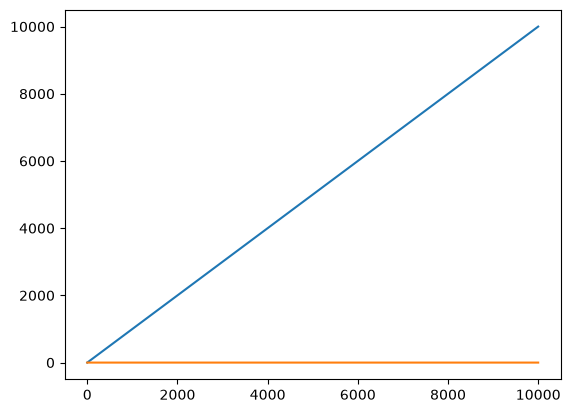

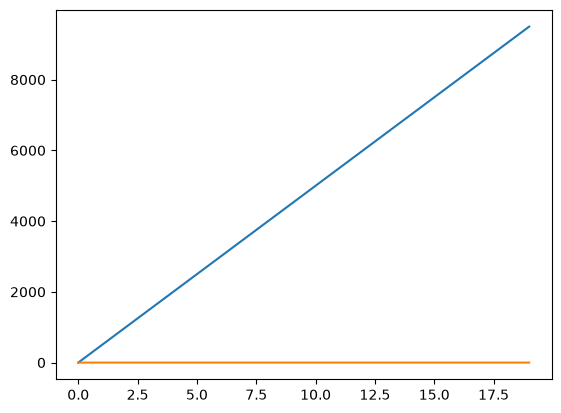

In [50]:
plt.plot(range(len(losses)), losses)
plt.show()

plt.plot(range(len(val_losses)), val_losses)
plt.show()

In [ ]:
def get_total_steps_mse(X, standardised_y, config, chunk_size=2**14):
    sq_err_sum = 0.0
    with T.no_grad():
        for i in range(0, len(X), chunk_size):
            xb = F.one_hot(X[i:i+chunk_size] + 2, 5).float().flatten(1)
            preds = network(xb).squeeze(-1) * config['std'] + config['mean']
            target = standardised_y[i:i+chunk_size] * config['std'] + config['mean']
            sq_err_sum += F.mse_loss(preds, target, reduction='sum').item()
    return sq_err_sum / len(X)

def save_network():
    now = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
    folder = 'runs/'+now
    os.makedirs(folder, exist_ok=True)
    with open(folder+"/config.json", "w", encoding='utf-8') as f:
        json.dump(config, f, indent=4)
    T.save(network.state_dict(), 'runs/'+now+"/model.pt")
    pd.DataFrame(losses, columns=['step','loss']).to_csv(folder+'/train_losses.csv', index=False)
    pd.DataFrame(val_losses, columns=['step','loss']).to_csv(folder+'/val_losses.csv', index=False)
    metrics = {
        'train_set_MSE_in_steps' : get_total_steps_mse(X_train, y_train, config),
        'val_set_MSE_in_steps' : get_total_steps_mse(X_val, y_val, config),
        'test_set_MSE_in_steps' : get_total_steps_mse(X_test, y_test, config),
    }
    with open(folder+"/metrics.json", "w", encoding='utf-8') as f:
        json.dump(metrics, f, indent=4)
    shutil.copy('train_network.ipynb', folder + '/train_network.ipynb')
save_network()

torch.Size([257404, 2, 100]) torch.Size([257404])
